# Indian Telecom Customer Churn Analysis

**Type:** Exploratory data analysis (EDA) and business recommendations  
**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn

## Business problem
A telecom company is losing customers and wants to know **why they leave** and **what it can do to keep them**. This notebook cleans the customer data, analyses churn from several angles, and turns the findings into recommendations the retention team can act on.

## Business questions this notebook answers

| # | Business question | Section |
|---|---|---|
| Q1 | What percentage of customers are churning? | Q1 |
| Q2 | Which telecom operators have the highest churn? | Q2 |
| Q3 | Are prepaid customers more likely to churn than postpaid customers? | Q3 |
| Q4 | Does customer tenure influence churn? | Q4 |
| Q5 | Do network complaints (and how they are handled) increase churn? | Q5 |
| Q6 | Does recharge behaviour signal a risk of churn? | Q6 |
| Q7 | Which customer segments are most likely to leave? | Q7 |
| Q8 | What can the company do to reduce churn? | Q8 |


## 1. Setup
Import the libraries used throughout the notebook and set display options.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Show every column when printing a DataFrame (the dataset has 21 columns)
pd.set_option('display.max_columns', None)

# Consistent chart style for the whole notebook
sns.set_theme(style='whitegrid')
BAR_COLOR = '#4C72B0'

# Folder where charts are saved (these are also used in the README)
os.makedirs('images', exist_ok=True)

def save_fig(name):
    """Save the current chart to images/<name>.png"""
    plt.savefig(f'images/{name}.png', dpi=130, bbox_inches='tight')

def add_labels(ax, fmt='%.1f%%'):
    """Write the value on top of every bar so charts can be read without a y-axis"""
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, padding=3)

## 2. Load the data

In [ ]:
df = pd.read_csv('data/india_telecom_churn_synthetic.csv')

In [ ]:
df.head()

,customer_id,operator,plan_type,age,gender,circle,area_type,tenure_months,monthly_recharge_inr,avg_data_gb,avg_call_minutes,sms_sent,device_type,is_5g_user,payment_mode,network_complaints,customer_care_calls,complaint_resolved,recharge_gap_days,num_recharges_6m,churn
0,IN107622,Jio,Prepaid,47.0,Female,Tamil Nadu,Semi-urban,26,199,3.1,10,18,Android,0,Cash/Retailer,0,0.0,No complaint,3,3,0
1,IN100065,Airtel,Postpaid,24.0,Male,Telangana,Semi-urban,7,1499,25.8,311,25,Android,0,UPI,1,3.0,No,13,6,0
2,IN104983,Jio,Prepaid,18.0,Male,Tamil Nadu,Urban,65,479,24.4,217,29,Android,1,UPI,0,1.0,No complaint,13,1,0
3,IN101637,BSNL,Prepaid,18.0,Female,Telangana,Semi-urban,5,299,2.7,381,22,Android,0,UPI,1,0.0,No,6,5,0
4,IN109359,Jio,Prepaid,18.0,Female,Maharashtra,Urban,36,239,8.8,173,23,Android,0,Cash/Retailer,0,0.0,No complaint,10,10,0


## 3. Data inspection
**Goal:** before analysing anything, check the size, data types, missing values, duplicates and unusual values. Bad data leads to wrong conclusions.

In [ ]:
# Size of the dataset
df.shape

(10040, 21)

In [5]:
# List of all column names
df.columns.tolist()

['customer_id',
 'operator',
 'plan_type',
 'age',
 'gender',
 'circle',
 'area_type',
 'tenure_months',
 'monthly_recharge_inr',
 'avg_data_gb',
 'avg_call_minutes',
 'sms_sent',
 'device_type',
 'is_5g_user',
 'payment_mode',
 'network_complaints',
 'customer_care_calls',
 'complaint_resolved',
 'recharge_gap_days',
 'num_recharges_6m',
 'churn']

In [ ]:
# Data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10040 entries, 0 to 10039
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           10040 non-null  str    
 1   operator              10040 non-null  str    
 2   plan_type             10040 non-null  str    
 3   age                   9959 non-null   float64
 4   gender                10040 non-null  str    
 5   circle                10040 non-null  str    
 6   area_type             10040 non-null  str    
 7   tenure_months         10040 non-null  int64  
 8   monthly_recharge_inr  10040 non-null  int64  
 9   avg_data_gb           9837 non-null   float64
 10  avg_call_minutes      10040 non-null  int64  
 11  sms_sent              10040 non-null  int64  
 12  device_type           10040 non-null  str    
 13  is_5g_user            10040 non-null  int64  
 14  payment_mode          10040 non-null  str    
 15  network_complaints    10040 no

In [ ]:
df.describe()

,age,tenure_months,monthly_recharge_inr,avg_data_gb,avg_call_minutes,sms_sent,is_5g_user,network_complaints,customer_care_calls,recharge_gap_days,num_recharges_6m,churn
count,9959.000000,10040.000000,10040.000000,9837.000000,10040.000000,10040.000000,10040.000000,10040.000000,9874.000000,10040.000000,10040.000000,10040.000000
mean,34.159153,30.312052,424.727092,13.595293,349.969721,24.954781,0.331574,0.744124,0.955033,11.679183,4.942032,0.163247
std,10.336140,20.726595,398.442817,9.615515,157.559227,4.990752,0.470802,0.911114,1.114167,7.549139,2.232396,0.369609
min,18.000000,1.000000,199.000000,0.500000,10.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,26.000000,15.000000,239.000000,6.800000,241.000000,21.000000,0.000000,0.000000,0.000000,6.000000,3.000000,0.000000
50%,34.000000,26.000000,399.000000,11.300000,348.000000,25.000000,0.000000,1.000000,1.000000,10.000000,5.000000,0.000000
75%,41.000000,41.000000,499.000000,17.900000,456.000000,28.000000,1.000000,1.000000,1.000000,16.000000,6.000000,0.000000
max,74.000000,120.000000,9999.000000,107.800000,943.000000,44.000000,1.000000,6.000000,9.000000,58.000000,12.000000,1.000000


In [ ]:
# Missing values per column
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': df.isnull().mean() * 100
})
missing = missing.sort_values(by='Missing_Percentage', ascending=False)
print(missing)

                      Missing_Count  Missing_Percentage
avg_data_gb                     203            2.021912
customer_care_calls             166            1.653386
age                              81            0.806773
customer_id                       0            0.000000
operator                          0            0.000000
gender                            0            0.000000
plan_type                         0            0.000000
tenure_months                     0            0.000000
circle                            0            0.000000
monthly_recharge_inr              0            0.000000
avg_call_minutes                  0            0.000000
sms_sent                          0            0.000000
area_type                         0            0.000000
device_type                       0            0.000000
is_5g_user                        0            0.000000
payment_mode                      0            0.000000
network_complaints                0            0

In [ ]:
# Exact duplicate rows
df.duplicated().sum()

np.int64(40)

In [ ]:
# Duplicate customer IDs
df['customer_id'].duplicated().sum()

np.int64(40)

In [ ]:
df[df['customer_id'].duplicated(keep=False)].sort_values('customer_id').head(10)

,customer_id,operator,plan_type,age,gender,circle,area_type,tenure_months,monthly_recharge_inr,avg_data_gb,avg_call_minutes,sms_sent,device_type,is_5g_user,payment_mode,network_complaints,customer_care_calls,complaint_resolved,recharge_gap_days,num_recharges_6m,churn
6382,IN100130,Jio,Postpaid,63.0,Male,Rajasthan,Rural,57,799,18.9,410,25,Android,0,UPI,0,0.0,No complaint,0,5,0
1621,IN100130,Jio,Postpaid,63.0,Male,Rajasthan,Rural,57,799,18.9,410,25,Android,0,UPI,0,0.0,No complaint,0,5,0
8725,IN100574,Vi,Prepaid,41.0,Female,Rajasthan,Semi-urban,43,479,NaN,732,21,Android,0,UPI,0,0.0,No complaint,6,6,0
2094,IN100574,Vi,Prepaid,41.0,Female,Rajasthan,Semi-urban,43,479,NaN,732,21,Android,0,UPI,0,0.0,No complaint,6,6,0
9572,IN101217,Airtel,Prepaid,37.0,Male,Rajasthan,Rural,22,299,22.0,100,42,Android,0,UPI,1,1.0,Yes,14,4,0
1750,IN101217,Airtel,Prepaid,37.0,Male,Rajasthan,Rural,22,299,22.0,100,42,Android,0,UPI,1,1.0,Yes,14,4,0
5342,IN101266,Jio,Prepaid,29.0,Male,Uttar Pradesh,Urban,30,199,6.2,360,26,Android,0,Cash/Retailer,0,1.0,No complaint,0,2,0
5125,IN101266,Jio,Prepaid,29.0,Male,Uttar Pradesh,Urban,30,199,6.2,360,26,Android,0,Cash/Retailer,0,1.0,No complaint,0,2,0
7472,IN101520,Jio,Prepaid,33.0,Female,Gujarat,Semi-urban,4,299,12.5,199,23,Android,1,UPI,0,1.0,No complaint,10,6,0
8488,IN101520,Jio,Prepaid,33.0,Female,Gujarat,Semi-urban,4,299,12.5,199,23,Android,1,UPI,0,1.0,No complaint,10,6,0


In [12]:
# Outlier check on monthly recharge amount.
# Valid plans in this dataset range from about 199 to 1,499 INR, so anything far above is suspicious.
print(df['monthly_recharge_inr'].describe())
print()
suspicious = df[df['monthly_recharge_inr'] > 1500]
print('Rows with recharge above 1,500 INR:', len(suspicious))
print(suspicious['monthly_recharge_inr'].value_counts())
print(suspicious['plan_type'].value_counts())

count    10040.000000
mean       424.727092
std        398.442817
min        199.000000
25%        239.000000
50%        399.000000
75%        499.000000
max       9999.000000
Name: monthly_recharge_inr, dtype: float64

Rows with recharge above 1,500 INR: 12
monthly_recharge_inr
9999    12
Name: count, dtype: int64
plan_type
Prepaid    12
Name: count, dtype: int64


### What the inspection shows
- **Size:** 10,040 rows and 21 columns.
- **Duplicates:** 40 rows are exact copies of other rows (same `customer_id`), so the data holds 10,000 unique customers.
- **Missing values:** three columns have gaps: `avg_data_gb` (about 2.0%), `customer_care_calls` (about 1.7%) and `age` (about 0.8%).
- **Outliers:** 12 rows show a monthly recharge of 9,999 INR. This looks like a placeholder or data-entry error, since no plan costs that much. All 12 are prepaid customers, whose real plans stay under 1,000 INR.

**Cleaning plan:** remove duplicates, fill missing values using the median, and replace the 9,999 INR values with the typical (median) recharge for the same plan type.

## 4. Data cleaning
Work on a copy so the raw data stays untouched and can be reloaded at any time.

In [ ]:
# Keep the original DataFrame unchanged
df_clean = df.copy()

In [14]:
# Step 1: remove the 40 duplicate rows (keeps the first copy of each)
df_clean = df_clean.drop_duplicates()

In [15]:
# Step 2: decide how to fill missing values.
# Compare mean, median and skewness: if a column is skewed, the median is a safer fill value than the mean.
for col in ['age', 'avg_data_gb', 'customer_care_calls']:
    print(f"\nColumn: {col}")
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Skewness:", df[col].skew())


Column: age
Mean: 34.15915252535395
Median: 34.0
Skewness: 0.3377194029730509

Column: avg_data_gb
Mean: 13.59529328047169
Median: 11.3
Skewness: 1.7325368426175582

Column: customer_care_calls
Mean: 0.9550334211059348
Median: 1.0
Skewness: 1.4356507848827829


In [16]:
# Fill missing values with the median (not affected by extreme values)
df_clean['age'] = df_clean['age'].fillna(df_clean['age'].median())
df_clean['avg_data_gb'] = df_clean['avg_data_gb'].fillna(df_clean['avg_data_gb'].median())
df_clean['customer_care_calls'] = df_clean['customer_care_calls'].fillna(df_clean['customer_care_calls'].median())

In [17]:
# Step 3: fix the 9,999 INR recharge placeholders.
# Replace them with the median recharge of the same plan type, calculated from valid rows only.
valid = df_clean['monthly_recharge_inr'] <= 1500
plan_median = df_clean[valid].groupby('plan_type')['monthly_recharge_inr'].median()
print("Median recharge by plan type used for the fix:")
print(plan_median)

outlier_mask = ~valid
df_clean.loc[outlier_mask, 'monthly_recharge_inr'] = df_clean.loc[outlier_mask, 'plan_type'].map(plan_median)

print("\nRecharge values above 1,500 INR remaining:", (df_clean['monthly_recharge_inr'] > 1500).sum())

Median recharge by plan type used for the fix:
plan_type
Postpaid    599.0
Prepaid     299.0
Name: monthly_recharge_inr, dtype: float64

Recharge values above 1,500 INR remaining: 0


In [18]:
# Step 4: verify the result. Expected: 0 missing values and 10,000 rows.
print("Missing values left:", df_clean.isnull().sum().sum())
print("Shape after cleaning:", df_clean.shape)
print("Unique customer IDs:", df_clean['customer_id'].is_unique)

Missing values left: 0
Shape after cleaning: (10000, 21)
Unique customer IDs: True


In [ ]:
# Step 5: check categorical columns for inconsistent spellings 
categorical_cols = df_clean.select_dtypes(exclude='number').columns
for col in categorical_cols:
    if col != 'customer_id':
        print(f"\n{col}")
        print(df_clean[col].value_counts())


operator
operator
Jio       4034
Airtel    3329
Vi        1652
BSNL       985
Name: count, dtype: int64

plan_type
plan_type
Prepaid     8194
Postpaid    1806
Name: count, dtype: int64

gender
gender
Male      5777
Female    4223
Name: count, dtype: int64

circle
circle
Uttar Pradesh    1832
Maharashtra      1399
Delhi             978
Tamil Nadu        946
Karnataka         850
Rajasthan         824
Telangana         812
Gujarat           804
West Bengal       796
Bihar             759
Name: count, dtype: int64

area_type
area_type
Urban         4528
Semi-urban    2965
Rural         2507
Name: count, dtype: int64

device_type
device_type
Android          7963
Feature phone    1037
iPhone           1000
Name: count, dtype: int64

payment_mode
payment_mode
UPI              5563
Cash/Retailer    1981
Card             1472
Net banking       984
Name: count, dtype: int64

complaint_resolved
complaint_resolved
No complaint    4924
Yes             3268
No              1808
Name: count, dtype

In [ ]:
# Save the cleaned dataset
df_clean.to_csv('data/india_telecom_churn_cleaned.csv', index=False)
print("Saved: data/india_telecom_churn_cleaned.csv")

Saved: data/india_telecom_churn_cleaned.csv


### Cleaning summary

| Issue | Rows affected | Action |
|---|---|---|
| Duplicate records | 40 | Removed |
| Missing `avg_data_gb` | 203 | Filled with median |
| Missing `customer_care_calls` | 166 | Filled with median |
| Missing `age` | 81 | Filled with median |
| Recharge placeholder (9,999 INR) | 12 | Replaced with the median of the same plan type |

The cleaned dataset has **10,000 unique customers** and no missing values.

## 5. Exploratory analysis and business questions

### Q1. What percentage of customers are churning?
**Why it matters:** the overall churn rate is the baseline KPI. Every retention action is judged against it.

In [21]:
# Number of retained (0) and churned (1) customers
df_clean['churn'].value_counts()

churn
0    8370
1    1630
Name: count, dtype: int64

In [22]:
# Same split as a percentage
df_clean['churn'].value_counts(normalize=True) * 100

churn
0    83.7
1    16.3
Name: proportion, dtype: float64

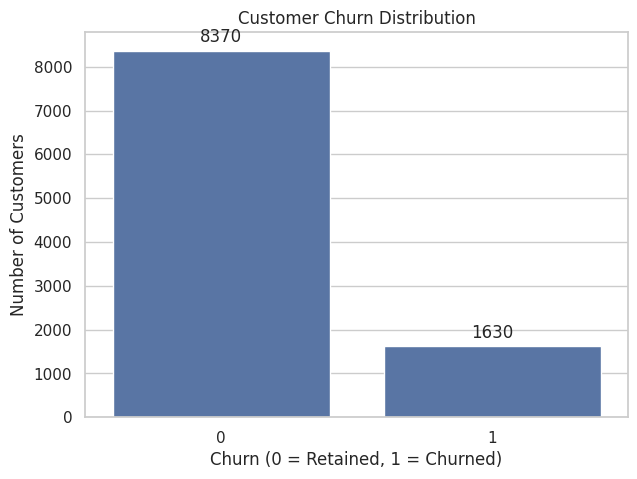

In [23]:
# Overall churn distribution
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df_clean, x='churn', color=BAR_COLOR)
ax.bar_label(ax.containers[0], padding=3)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Customers")
save_fig('01_churn_distribution')
plt.show()

**Finding:** 1,630 of 10,000 customers churned, an overall churn rate of **16.3%**. About 1 in 6 customers leaves.

**Solution / action:** use 16.3% as the baseline retention KPI and track it monthly by operator, plan and segment. The data is imbalanced (84% retained), so later modelling should be judged on recall and precision, not accuracy alone.

### Q2. Which telecom operators have the highest churn?
**Why it matters:** it shows where to focus network, pricing and service improvements first.

operator
Vi        24.21
BSNL      23.25
Airtel    14.99
Jio       12.44
Name: churn, dtype: float64


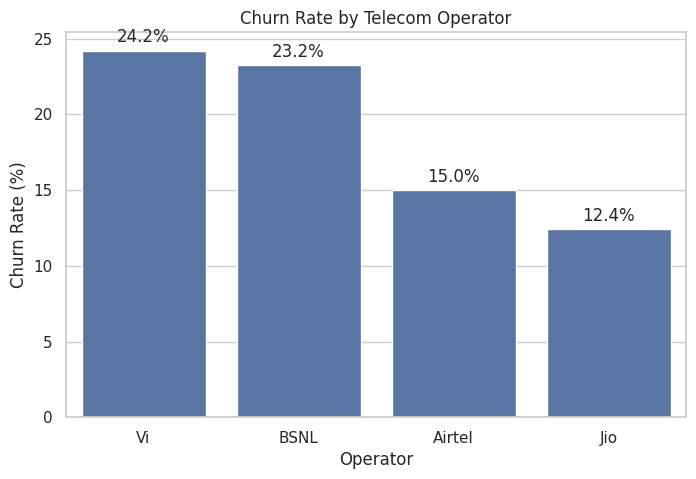

In [24]:
# Churn rate (%) by operator: the mean of a 0/1 column is the share of churned customers
churn_operator = (df_clean.groupby('operator')['churn'].mean() * 100).sort_values(ascending=False)
print(churn_operator.round(2))

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=churn_operator.index, y=churn_operator.values, color=BAR_COLOR)
add_labels(ax)

plt.title("Churn Rate by Telecom Operator")
plt.xlabel("Operator")
plt.ylabel("Churn Rate (%)")
save_fig('02_churn_by_operator')
plt.show()

**Finding:** Vi has the highest churn (**24.2%**), followed by BSNL (**23.2%**). Airtel is at 15.0% and Jio is lowest at **12.4%**. Vi customers churn at almost twice the rate of Jio customers.

**Solution / action:** start with Vi and BSNL. Audit network quality and complaint handling for these two operators, benchmark their service against Jio and Airtel, and run win-back and loyalty offers aimed at their at-risk customers.

### Q3. Are prepaid customers more likely to churn than postpaid customers?
**Why it matters:** prepaid customers can leave without notice, while postpaid customers are tied to a billing relationship.

,plan_type,total_customers,churned_customers,churn_rate
0,Postpaid,1806,246,13.621262
1,Prepaid,8194,1384,16.890408


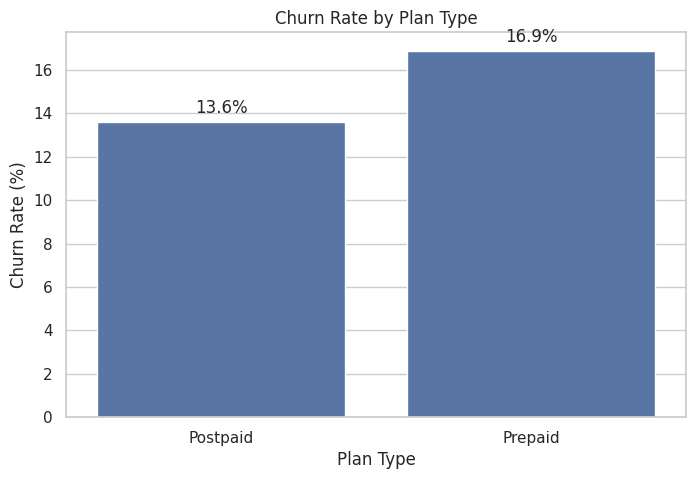

In [25]:
# Churn by plan type, with customer counts so the sample size is visible
plan_churn = (
    df_clean.groupby('plan_type')
    .agg(
        total_customers=('churn', 'count'),
        churned_customers=('churn', 'sum'),
        churn_rate=('churn', 'mean')
    )
    .reset_index()
)
plan_churn['churn_rate'] *= 100
display(plan_churn)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=plan_churn, x='plan_type', y='churn_rate', color=BAR_COLOR)
add_labels(ax)

plt.title("Churn Rate by Plan Type")
plt.xlabel("Plan Type")
plt.ylabel("Churn Rate (%)")
save_fig('03_churn_by_plan')
plt.show()

,operator,plan_type,total_customers,churned_customers,churn_rate
7,Vi,Prepaid,1358,344,25.331370
3,BSNL,Prepaid,792,189,23.863636
2,BSNL,Postpaid,193,40,20.725389
6,Vi,Postpaid,294,56,19.047619
1,Airtel,Prepaid,2748,424,15.429403
5,Jio,Prepaid,3296,427,12.955097
0,Airtel,Postpaid,581,75,12.908778
4,Jio,Postpaid,738,75,10.162602


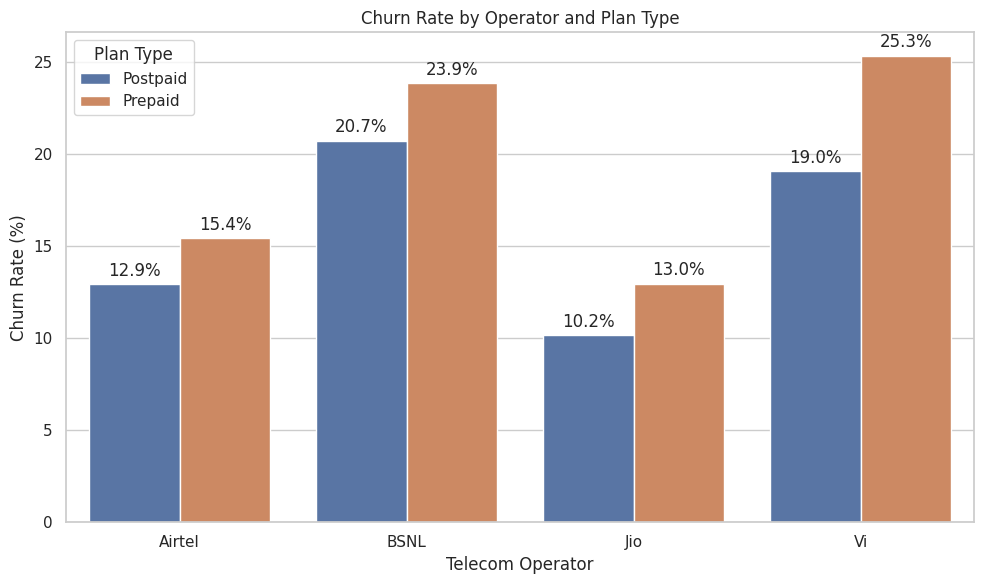

In [26]:
# Is the prepaid/postpaid gap the same for every operator? Check each operator-plan combination.
operator_plan_churn = (
    df_clean.groupby(['operator', 'plan_type'])
    .agg(
        total_customers=('churn', 'count'),
        churned_customers=('churn', 'sum'),
        churn_rate=('churn', 'mean')
    )
    .reset_index()
)

operator_plan_churn['churn_rate'] *= 100
display(operator_plan_churn.sort_values('churn_rate', ascending=False))

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=operator_plan_churn,
    x='operator',
    y='churn_rate',
    hue='plan_type'
)
add_labels(ax)

plt.title('Churn Rate by Operator and Plan Type')
plt.xlabel('Telecom Operator')
plt.ylabel('Churn Rate (%)')
plt.legend(title='Plan Type')

plt.tight_layout()
save_fig('04_churn_by_operator_plan')
plt.show()

**Finding:** prepaid customers churn more (**16.9%**) than postpaid customers (**13.6%**), and this holds for every operator. The operator matters more than the plan: Vi postpaid (19.0%) churns more than Airtel prepaid (15.4%). The highest-risk segment is **Vi prepaid (25.3%, 1,358 customers)**; the lowest is **Jio postpaid (10.2%)**.

**Solution / action:** encourage prepaid customers to build a habit that is hard to leave: auto-recharge (for example UPI AutoPay), long-validity plans and rewards for consecutive recharges. Offer eligible high-usage prepaid users a move to postpaid.

### Q4. Does customer tenure influence churn?
**Why it matters:** if customers leave early, the company needs stronger onboarding; if they leave late, it needs loyalty programs.

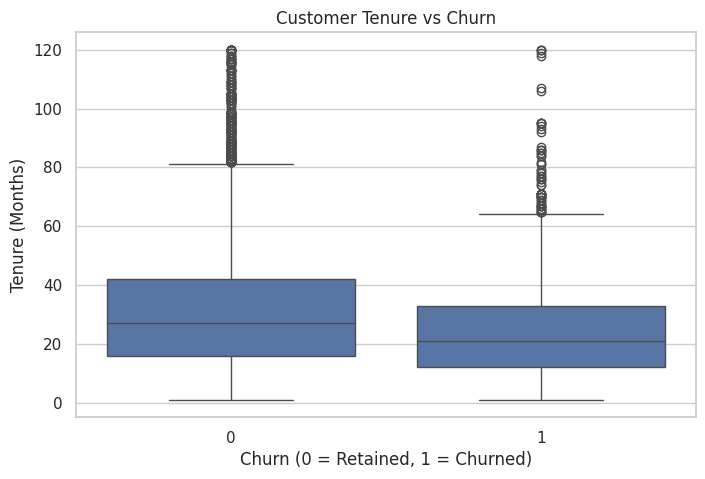

In [27]:
# Compare how long churned and retained customers have been with the company
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x='churn', y='tenure_months', color=BAR_COLOR)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Tenure (Months)")
save_fig('05_tenure_boxplot')
plt.show()

tenure_group
0-6 Months     26.08
6-12 Months    20.10
1-2 Years      18.67
2-5 Years      13.37
5+ Years       10.56
Name: churn, dtype: float64


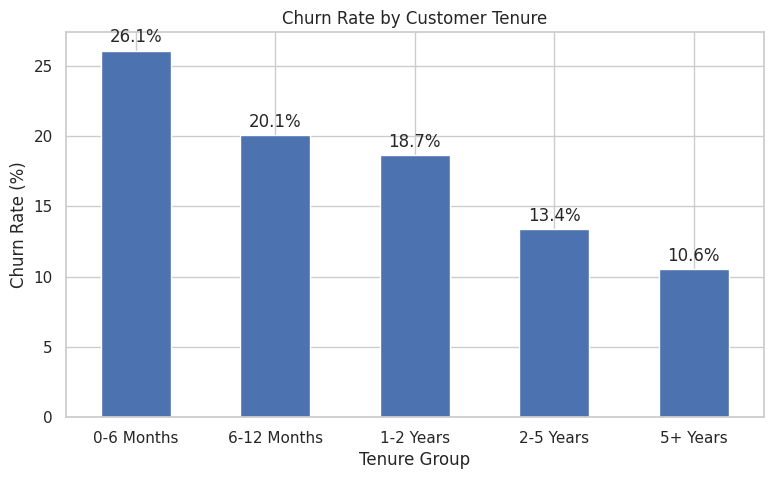

In [28]:
# Group tenure into life-stage buckets so the pattern is easier to read
df_clean['tenure_group'] = pd.cut(
    df_clean['tenure_months'],
    bins=[0, 6, 12, 24, 60, 120],
    labels=[
        '0-6 Months',
        '6-12 Months',
        '1-2 Years',
        '2-5 Years',
        '5+ Years'
    ],
    include_lowest=True
)

tenure_churn = df_clean.groupby(
    'tenure_group',
    observed=False
)['churn'].mean() * 100

print(tenure_churn.round(2))

ax = tenure_churn.plot(
    kind='bar',
    figsize=(9, 5),
    title="Churn Rate by Customer Tenure",
    color=BAR_COLOR
)
add_labels(ax)

plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
save_fig('06_churn_by_tenure')
plt.show()

**Finding:** churn falls steadily as tenure grows: **26.1%** for customers in their first 6 months, 20.1% at 6-12 months, 13.4% at 2-5 years and **10.6%** after 5 years. Newer customers are about 2.5 times as likely to leave as the longest-standing ones.

**Solution / action:** build an onboarding and early-life program for the first 6 months: a welcome call, a first-recharge incentive, usage tips, and a check-in at days 30, 60 and 90. Reducing early churn gives the largest return per customer.

### Q5. Do network complaints increase churn?
**Why it matters:** complaints are a direct signal of poor service, and they can be acted on immediately.

,network_complaints,total_customers,churned_customers,churn_rate
0,0,4924,513,10.418359
1,1,3339,590,17.669961
2,2,1258,332,26.391097
3,3,360,133,36.944444
4,4,93,48,51.612903
5,5,18,8,44.444444
6,6,8,6,75.000000


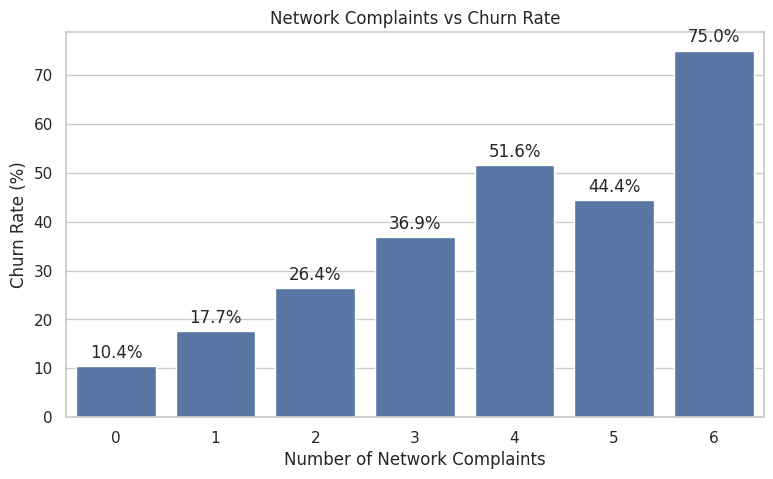

In [29]:
# Churn rate by number of network complaints, with customer counts
complaint_count_churn = (
    df_clean.groupby('network_complaints')
    .agg(
        total_customers=('churn', 'count'),
        churned_customers=('churn', 'sum'),
        churn_rate=('churn', 'mean')
    )
    .reset_index()
)
complaint_count_churn['churn_rate'] *= 100
display(complaint_count_churn)

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=complaint_count_churn, x='network_complaints', y='churn_rate', color=BAR_COLOR)
add_labels(ax)

plt.title("Network Complaints vs Churn Rate")
plt.xlabel("Number of Network Complaints")
plt.ylabel("Churn Rate (%)")
save_fig('07_churn_by_complaints')
plt.show()

,complaint_resolved,total_customers,churned_customers,churn_rate
0,No,1808,468,25.884956
1,No complaint,4924,513,10.418359
2,Yes,3268,649,19.859241


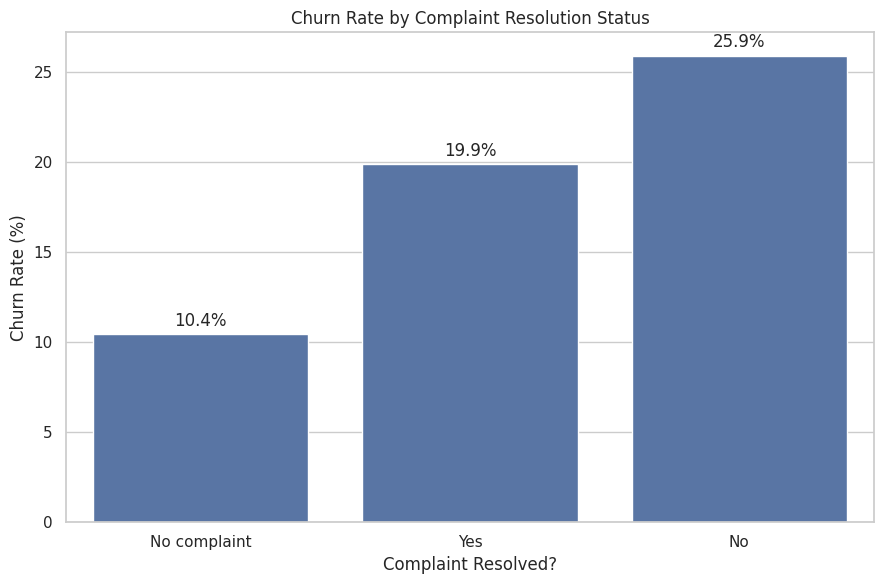

In [30]:
# Does it matter whether the complaint was resolved?
complaint_churn = (
    df_clean.groupby('complaint_resolved')
    .agg(
        total_customers=('churn', 'count'),
        churned_customers=('churn', 'sum'),
        churn_rate=('churn', 'mean')
    )
    .reset_index()
)

complaint_churn['churn_rate'] *= 100
display(complaint_churn)

plt.figure(figsize=(9, 6))
ax = sns.barplot(
    data=complaint_churn,
    x='complaint_resolved',
    y='churn_rate',
    order=['No complaint', 'Yes', 'No'],
    color=BAR_COLOR
)
add_labels(ax)

plt.title('Churn Rate by Complaint Resolution Status')
plt.xlabel('Complaint Resolved?')
plt.ylabel('Churn Rate (%)')

plt.tight_layout()
save_fig('08_churn_by_complaint_resolution')
plt.show()

**Finding:** churn rises with every additional complaint: **10.4%** with none, 17.7% with one, 26.4% with two, 36.9% with three and 51.6% with four. (Customers with 5 or more complaints are too few, 26 in total, to read much into.) Complaint count is the strongest numeric link to churn in the data. How the complaint is handled matters too: customers with an **unresolved** complaint churn at **25.9%**, versus 19.9% when it was resolved and 10.4% when there was no complaint.

Even resolved complainers churn at nearly double the rate of customers with no complaint, so a fix alone does not win the customer back.

**Solution / action:**
- Set a resolution deadline (SLA) for network complaints and track the percentage of complaints closed on time.
- Treat the **second complaint** as an alert: assign a senior agent and contact the customer proactively.
- After a resolution, follow up with a call and a goodwill gesture such as bonus data, so the customer feels heard.

### Q6. Does recharge behaviour signal a risk of churn?
**Why it matters:** in prepaid, a customer who stops recharging is already leaving. Recharge patterns can act as an early-warning system.

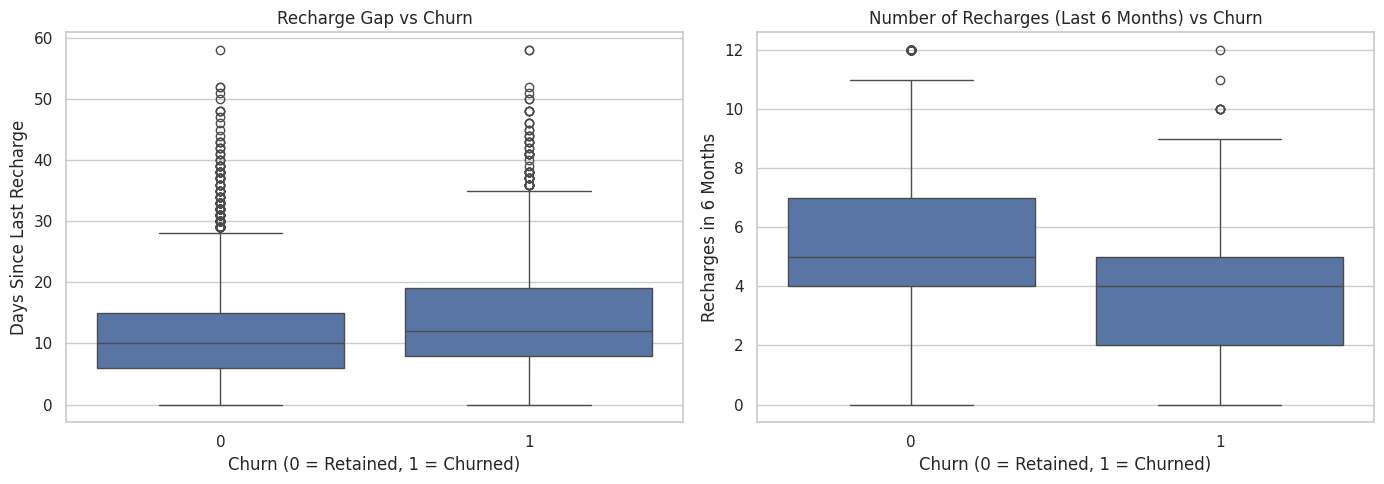

In [31]:
# Compare recharge gap and recharge frequency for churned vs retained customers
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_clean, x='churn', y='recharge_gap_days', color=BAR_COLOR, ax=axes[0])
axes[0].set_title("Recharge Gap vs Churn")
axes[0].set_xlabel("Churn (0 = Retained, 1 = Churned)")
axes[0].set_ylabel("Days Since Last Recharge")

sns.boxplot(data=df_clean, x='churn', y='num_recharges_6m', color=BAR_COLOR, ax=axes[1])
axes[1].set_title("Number of Recharges (Last 6 Months) vs Churn")
axes[1].set_xlabel("Churn (0 = Retained, 1 = Churned)")
axes[1].set_ylabel("Recharges in 6 Months")

plt.tight_layout()
save_fig('09_recharge_behaviour_boxplots')
plt.show()

In [32]:
# Average and median values for retained (0) vs churned (1) customers
recharge_summary = df_clean.groupby('churn')[
    ['recharge_gap_days', 'num_recharges_6m', 'monthly_recharge_inr']
].agg(['mean', 'median']).round(2)
display(recharge_summary)

recharge_gap_days        num_recharges_6m        monthly_recharge_inr  \
                   mean median             mean median                 mean   
churn                                                                         
0                 11.19   10.0             5.15    5.0               415.23   
1                 14.17   12.0             3.86    4.0               402.34   

              
      median  
churn         
0      399.0  
1      299.0

,gap_group,total_customers,churn_rate
0,0-10 days,5144,13.102644
1,11-20 days,3663,16.980617
2,21-30 days,948,24.367089
3,30+ days,245,42.040816


,recharge_freq_group,total_customers,churn_rate
0,0-2 recharges,1316,32.446809
1,3-4 recharges,3185,19.686028
2,5-6 recharges,3207,12.878079
3,7+ recharges,2292,7.111693


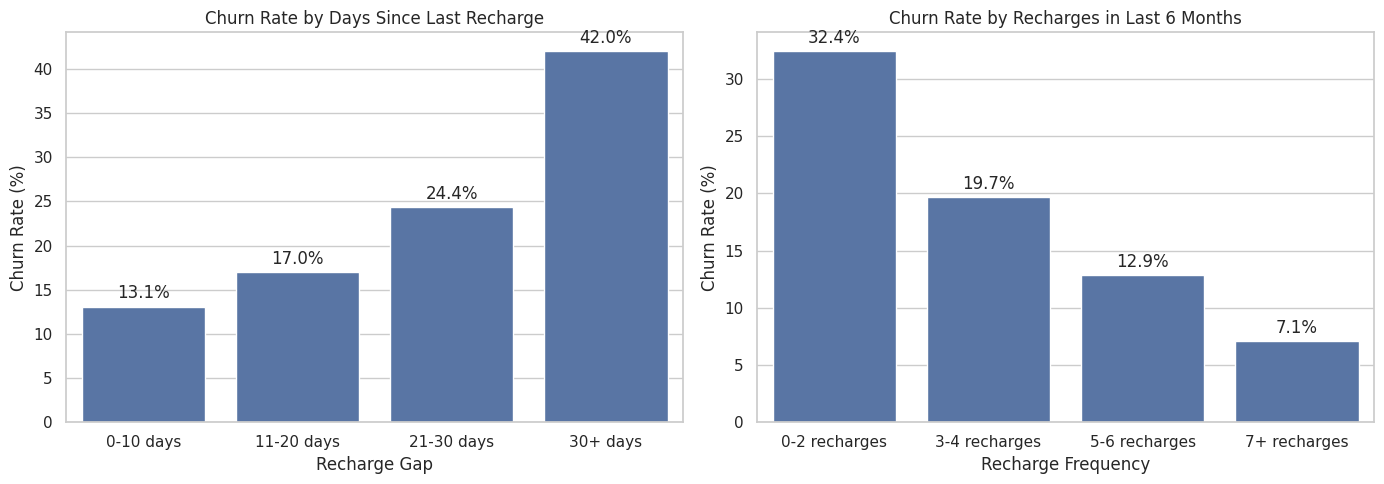

In [33]:
# Turn the behaviour into thresholds a retention team could actually use
df_clean['gap_group'] = pd.cut(
    df_clean['recharge_gap_days'],
    bins=[-1, 10, 20, 30, 90],
    labels=['0-10 days', '11-20 days', '21-30 days', '30+ days']
)
df_clean['recharge_freq_group'] = pd.cut(
    df_clean['num_recharges_6m'],
    bins=[-1, 2, 4, 6, 12],
    labels=['0-2 recharges', '3-4 recharges', '5-6 recharges', '7+ recharges']
)

gap_churn = (df_clean.groupby('gap_group', observed=True)
             .agg(total_customers=('churn', 'count'), churn_rate=('churn', 'mean')).reset_index())
freq_churn = (df_clean.groupby('recharge_freq_group', observed=True)
              .agg(total_customers=('churn', 'count'), churn_rate=('churn', 'mean')).reset_index())
gap_churn['churn_rate'] *= 100
freq_churn['churn_rate'] *= 100
display(gap_churn)
display(freq_churn)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=gap_churn, x='gap_group', y='churn_rate', color=BAR_COLOR, ax=axes[0])
add_labels(axes[0])
axes[0].set_title("Churn Rate by Days Since Last Recharge")
axes[0].set_xlabel("Recharge Gap")
axes[0].set_ylabel("Churn Rate (%)")

sns.barplot(data=freq_churn, x='recharge_freq_group', y='churn_rate', color=BAR_COLOR, ax=axes[1])
add_labels(axes[1])
axes[1].set_title("Churn Rate by Recharges in Last 6 Months")
axes[1].set_xlabel("Recharge Frequency")
axes[1].set_ylabel("Churn Rate (%)")

plt.tight_layout()
save_fig('10_churn_by_recharge_behaviour')
plt.show()

,recharge_group,total_customers,churned_customers,churn_rate
0,0-200,1503,272,18.097139
1,201-400,5021,832,16.570404
2,401-600,2373,370,15.592078
3,601-800,748,98,13.101604
4,801-1000,239,37,15.481172
5,1001-2000,116,21,18.103448


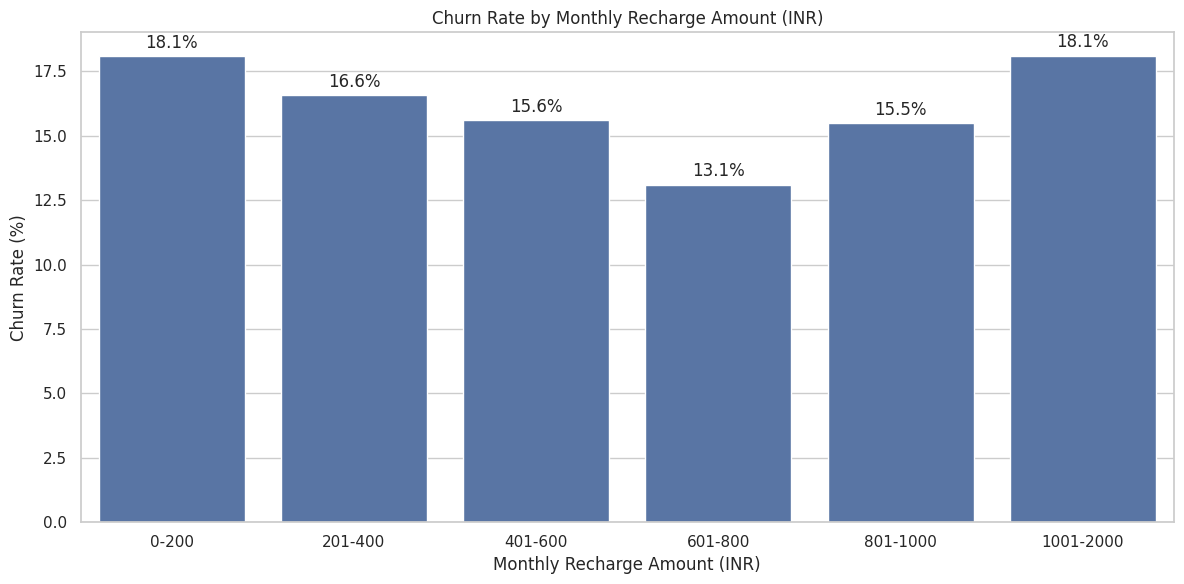

In [34]:
# Does the recharge AMOUNT (price) matter as much as recharge behaviour?
df_clean['recharge_group'] = pd.cut(
    df_clean['monthly_recharge_inr'],
    bins=[0, 200, 400, 600, 800, 1000, 2000],
    labels=['0-200', '201-400', '401-600', '601-800', '801-1000', '1001-2000'],
    include_lowest=True
)

recharge_churn = (
    df_clean.groupby('recharge_group', observed=True)
    .agg(
        total_customers=('churn', 'count'),
        churned_customers=('churn', 'sum'),
        churn_rate=('churn', 'mean')
    )
    .reset_index()
)

recharge_churn['churn_rate'] *= 100
display(recharge_churn)

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=recharge_churn, x='recharge_group', y='churn_rate', color=BAR_COLOR)
add_labels(ax)

plt.title('Churn Rate by Monthly Recharge Amount (INR)')
plt.xlabel('Monthly Recharge Amount (INR)')
plt.ylabel('Churn Rate (%)')

plt.tight_layout()
save_fig('11_churn_by_recharge_amount')
plt.show()

**Finding:** recharge behaviour is a strong warning sign.
- **Gap:** customers who go more than 30 days without recharging churn at **42.0%**, compared with 13.1% for those who recharge within 10 days. On average churned customers waited 14.2 days vs 11.2 days.
- **Frequency:** customers with 2 or fewer recharges in 6 months churn at **32.4%**, against 7.1% for those with 7 or more. Churned customers averaged 3.9 recharges vs 5.2.
- **Amount:** the recharge amount matters much less. Churn ranges between 13% and 18% across price bands with no clear trend, so price alone does not look like the main driver.

**Solution / action:** build an early-warning rule from billing data: flag a customer when the recharge gap passes **20 days** or recharges in 6 months drop to **2 or fewer**. Send a reminder or a targeted offer (for example a validity-extension or a small data pack) before the customer is gone. Prioritise service quality and engagement over broad price cuts.

### Q7. Which customer segments are most likely to leave?
**Why it matters:** retention budgets are limited. Targeting the riskiest segments gives the biggest saving per rupee spent.

We start with individual attributes (area, 5G, payment mode), then check how the factors relate, and finally combine them into segments and a simple risk score.

,area_type,total_customers,churned_customers,churn_rate
0,Rural,2507,508,20.263263
1,Semi-urban,2965,421,14.198988
2,Urban,4528,701,15.481449


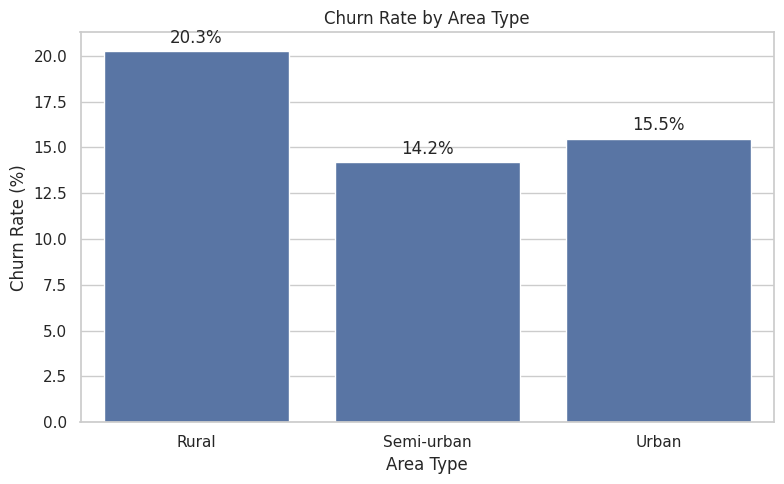

In [35]:
# Churn by area type (urban / semi-urban / rural)
area_churn = (
    df_clean.groupby('area_type')
    .agg(
        total_customers=('churn', 'count'),
        churned_customers=('churn', 'sum'),
        churn_rate=('churn', 'mean')
    )
    .reset_index()
)

area_churn['churn_rate'] *= 100
display(area_churn)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=area_churn, x='area_type', y='churn_rate', color=BAR_COLOR)
add_labels(ax)

plt.title('Churn Rate by Area Type')
plt.xlabel('Area Type')
plt.ylabel('Churn Rate (%)')

plt.tight_layout()
save_fig('12_churn_by_area')
plt.show()

,is_5g_user,total_customers,churned_customers,churn_rate
0,0,6684,1218,18.222621
1,1,3316,412,12.424608


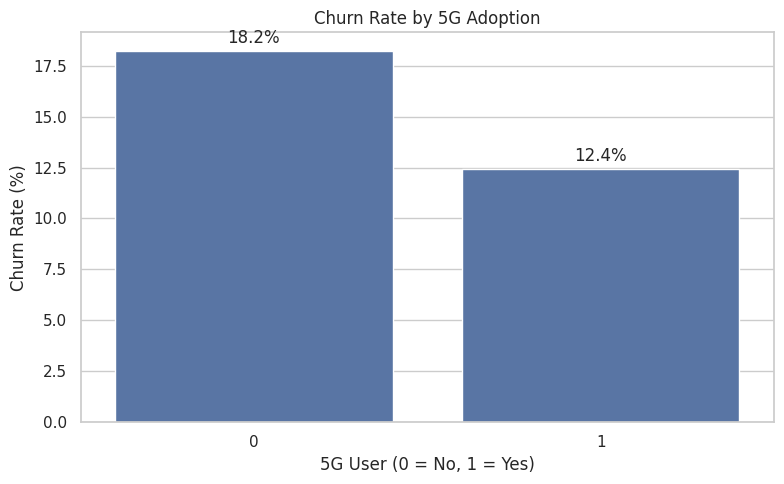

In [36]:
# Churn by 5G adoption
fiveg_churn = (
    df_clean.groupby('is_5g_user')
    .agg(
        total_customers=('churn', 'count'),
        churned_customers=('churn', 'sum'),
        churn_rate=('churn', 'mean')
    )
    .reset_index()
)

fiveg_churn['churn_rate'] *= 100
display(fiveg_churn)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=fiveg_churn, x='is_5g_user', y='churn_rate', color=BAR_COLOR)
add_labels(ax)

plt.title('Churn Rate by 5G Adoption')
plt.xlabel('5G User (0 = No, 1 = Yes)')
plt.ylabel('Churn Rate (%)')

plt.tight_layout()
save_fig('13_churn_by_5g')
plt.show()

,payment_mode,total_customers,churned_customers,churn_rate
0,Card,1472,227,15.421196
1,Cash/Retailer,1981,311,15.699142
2,Net banking,984,166,16.869919
3,UPI,5563,926,16.645695


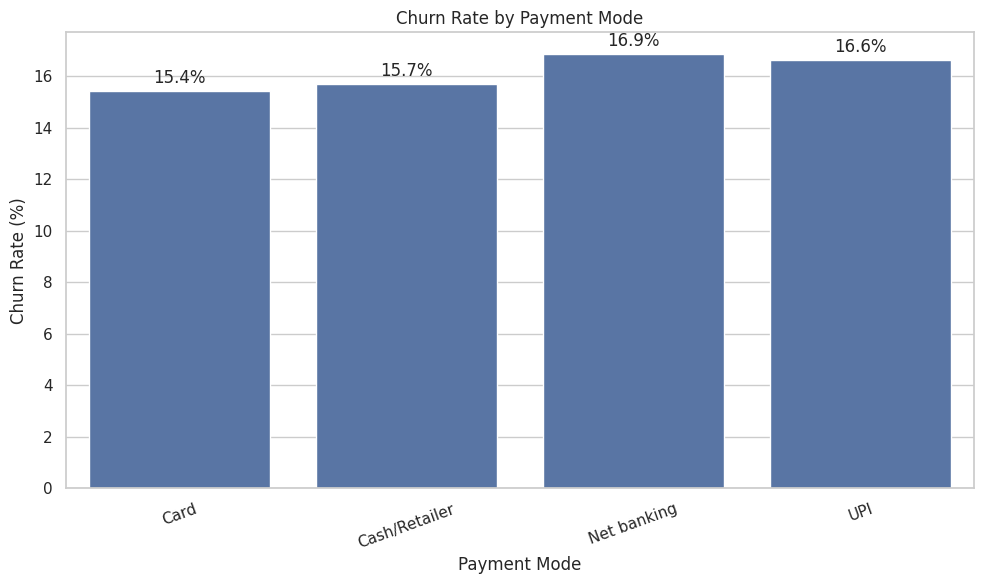

In [37]:
# Churn by payment mode
payment_churn = (
    df_clean.groupby('payment_mode')
    .agg(
        total_customers=('churn', 'count'),
        churned_customers=('churn', 'sum'),
        churn_rate=('churn', 'mean')
    )
    .reset_index()
)

payment_churn['churn_rate'] *= 100
display(payment_churn)

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=payment_churn, x='payment_mode', y='churn_rate', color=BAR_COLOR)
add_labels(ax)

plt.title('Churn Rate by Payment Mode')
plt.xlabel('Payment Mode')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=20)
plt.tight_layout()
save_fig('14_churn_by_payment_mode')
plt.show()

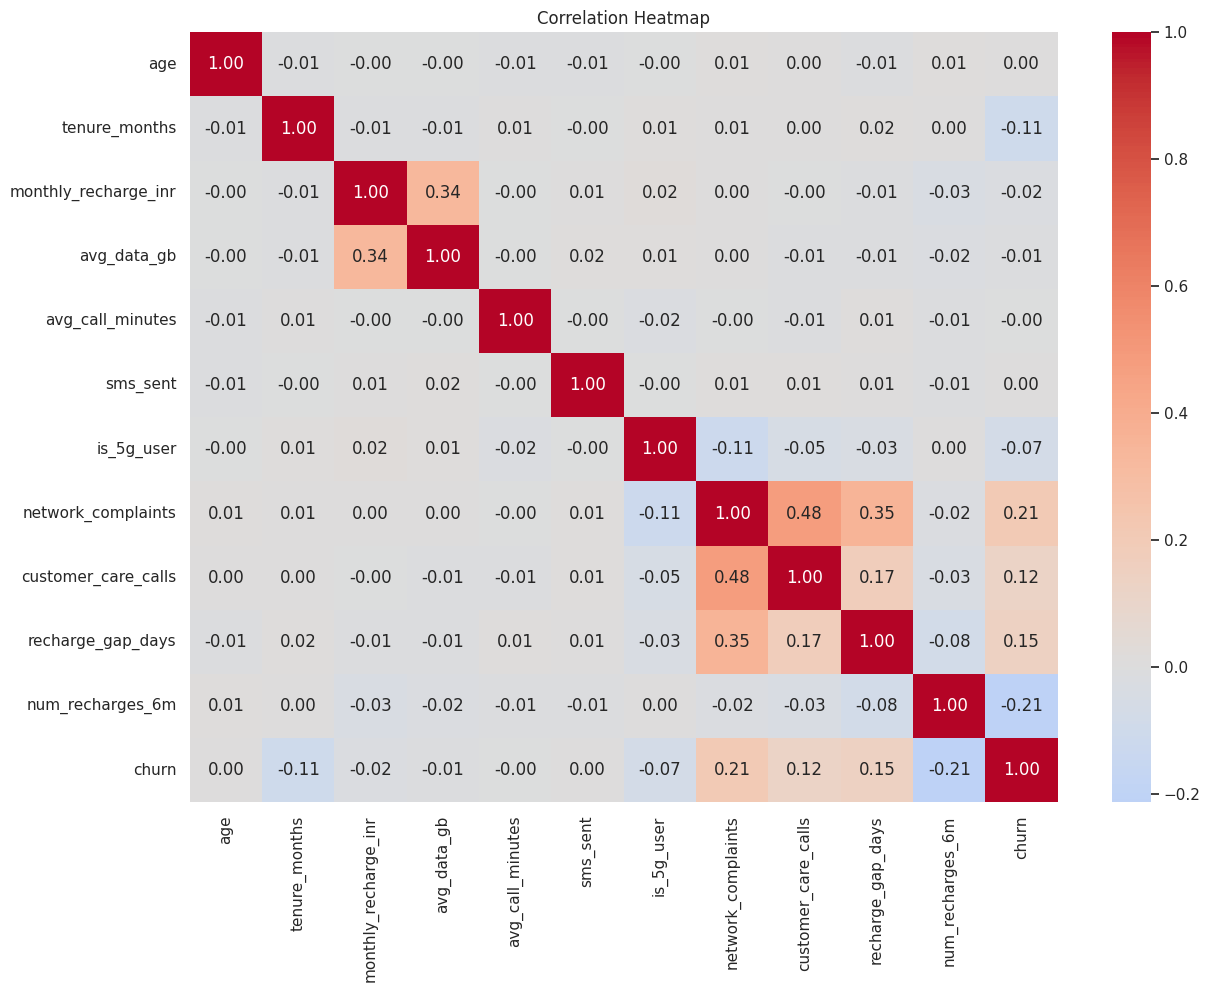

network_complaints      0.210
recharge_gap_days       0.146
customer_care_calls     0.120
sms_sent                0.004
age                     0.000
avg_call_minutes       -0.003
avg_data_gb            -0.009
monthly_recharge_inr   -0.021
is_5g_user             -0.074
tenure_months          -0.107
num_recharges_6m       -0.213
Name: churn, dtype: float64


In [38]:
# Correlation heatmap: which numeric features move together with churn?
# (Correlation shows association only, not cause and effect.)
numeric_cols = df_clean.select_dtypes(include=np.number).columns

plt.figure(figsize=(14, 10))
sns.heatmap(
    df_clean[numeric_cols].corr(),
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title("Correlation Heatmap")
save_fig('15_correlation_heatmap')
plt.show()

# Features ranked by correlation with churn
print(df_clean[numeric_cols].corr()['churn'].drop('churn').sort_values(ascending=False).round(3))

In [39]:
# Combine operator, plan and area to find the riskiest specific segments.
# Only segments with at least 100 customers are shown so that small samples do not mislead.
segments = (
    df_clean.groupby(['operator', 'plan_type', 'area_type'])
    .agg(total_customers=('churn', 'count'),
         churned_customers=('churn', 'sum'),
         churn_rate=('churn', 'mean'))
    .reset_index()
)
segments['churn_rate'] *= 100
segments = segments[segments['total_customers'] >= 100]

print("Highest-risk segments:")
display(segments.sort_values('churn_rate', ascending=False).head(5).round(2))
print("Lowest-risk segments:")
display(segments.sort_values('churn_rate').head(3).round(2))

Highest-risk segments:


,operator,plan_type,area_type,total_customers,churned_customers,churn_rate
21,Vi,Prepaid,Rural,346,119,34.39
9,BSNL,Prepaid,Rural,195,60,30.77
22,Vi,Prepaid,Semi-urban,406,95,23.40
11,BSNL,Prepaid,Urban,351,80,22.79
23,Vi,Prepaid,Urban,606,130,21.45


Lowest-risk segments:


,operator,plan_type,area_type,total_customers,churned_customers,churn_rate
13,Jio,Postpaid,Semi-urban,212,13,6.13
1,Airtel,Postpaid,Semi-urban,153,14,9.15
14,Jio,Postpaid,Urban,348,38,10.92


,risk_flags,total_customers,churned_customers,churn_rate
0,0,4580,387,8.45
1,1,3498,600,17.15
2,2,1436,415,28.90
3,3,410,180,43.90
4,4,69,42,60.87
5,5,7,6,85.71


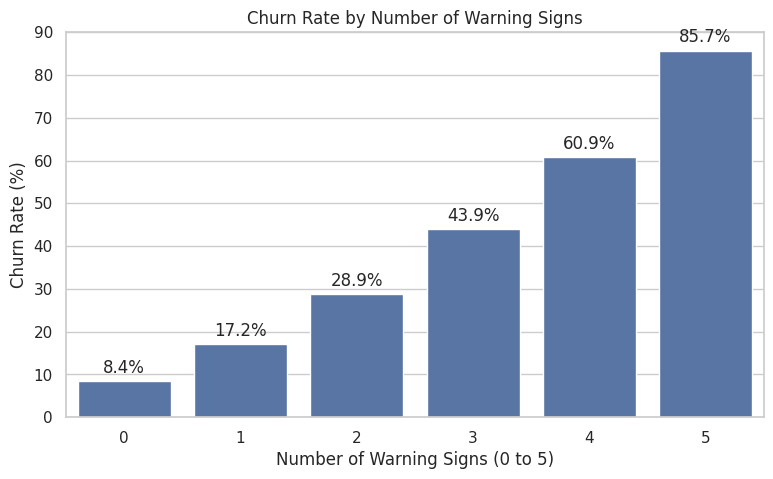

Customers with 3+ warning signs: 486 (4.9% of all customers)
Their churn rate: 46.9%
Share of all churners they contain: 14.0%


In [40]:
# A simple, explainable risk score: count how many warning signs each customer shows.
# Thresholds come from the analysis above (complaints, recharge behaviour, tenure).
df_clean['flag_unresolved_complaint'] = (df_clean['complaint_resolved'] == 'No').astype(int)
df_clean['flag_multiple_complaints']  = (df_clean['network_complaints'] >= 2).astype(int)
df_clean['flag_long_recharge_gap']    = (df_clean['recharge_gap_days'] > 20).astype(int)
df_clean['flag_low_recharge_count']   = (df_clean['num_recharges_6m'] <= 2).astype(int)
df_clean['flag_new_customer']         = (df_clean['tenure_months'] <= 12).astype(int)

flag_cols = [c for c in df_clean.columns if c.startswith('flag_')]
df_clean['risk_flags'] = df_clean[flag_cols].sum(axis=1)

risk_table = (
    df_clean.groupby('risk_flags')
    .agg(total_customers=('churn', 'count'),
         churned_customers=('churn', 'sum'),
         churn_rate=('churn', 'mean'))
    .reset_index()
)
risk_table['churn_rate'] *= 100
display(risk_table.round(2))

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=risk_table, x='risk_flags', y='churn_rate', color=BAR_COLOR)
add_labels(ax)
plt.title('Churn Rate by Number of Warning Signs')
plt.xlabel('Number of Warning Signs (0 to 5)')
plt.ylabel('Churn Rate (%)')
save_fig('16_churn_by_risk_flags')
plt.show()

# How well does the 3+ warning-sign group capture churners?
high_risk = df_clean[df_clean['risk_flags'] >= 3]
print(f"Customers with 3+ warning signs: {len(high_risk):,} ({len(high_risk) / len(df_clean):.1%} of all customers)")
print(f"Their churn rate: {high_risk['churn'].mean():.1%}")
print(f"Share of all churners they contain: {high_risk['churn'].sum() / df_clean['churn'].sum():.1%}")

**Findings**
- **Area:** rural customers churn the most (**20.3%**) versus urban 15.5% and semi-urban 14.2%.
- **5G:** 5G users churn less (**12.4%** vs 18.2%). This is an association; 5G users may also be urban, higher-value or better served, so 5G itself is not proven to reduce churn.
- **Payment mode:** all modes sit between 15.4% and 16.9%, so payment mode is not a useful churn signal.
- **Correlations:** the numeric features most linked with churn are network complaints (+0.21), recharge gap (+0.15), customer care calls (+0.12), tenure (-0.11), and recharges in 6 months (-0.21). Age, SMS usage, call minutes and data usage show almost no link.
- **Riskiest segments:** **Vi prepaid in rural areas (34.4%, 346 customers)** and **BSNL prepaid in rural areas (30.8%, 195 customers)**. The safest are Jio postpaid customers in semi-urban areas (6.1%).
- **Risk score:** churn climbs with each warning sign, from **8.4%** with none to **43.9%** with three and **60.9%** with four. The 486 customers with three or more signs churn at **46.9%**, about 3 times the average. Because the thresholds were chosen after looking at this same data, these rates are slightly optimistic and should be validated on new data.

**Solution / action**
- Focus rural network investment and retention offers on Vi and BSNL prepaid customers.
- Use the warning-sign score as a weekly watch list for the retention team and contact customers with 3 or more signs first.
- Do not spend effort on payment-mode campaigns; the differences are too small to matter.
- Consider promoting 5G upgrades to eligible customers, but test it on a small group first because the link may not be causal.

### Q8. What can the company do to reduce churn?
**Why it matters:** analysis only creates value when it leads to action. The cell below estimates how much revenue is at stake so that actions can be prioritised.

In [ ]:
# revenue-at-risk estimate.
# ASSUMPTIONS: annual revenue per customer = monthly recharge x 12,
# and a saved customer keeps the same recharge for the next 12 months.
churned = df_clean[df_clean['churn'] == 1]
annual_revenue_total = df_clean['monthly_recharge_inr'].sum() * 12
annual_revenue_lost = churned['monthly_recharge_inr'].sum() * 12

print(f"Estimated annual revenue of all customers : INR {annual_revenue_total:,.0f}")
print(f"Estimated annual revenue lost to churn    : INR {annual_revenue_lost:,.0f} ({annual_revenue_lost / annual_revenue_total:.1%})")

# Scenario: save 25% of the churners who sit in the 3+ warning-sign group
save_rate = 0.25
high_risk_churners = df_clean[(df_clean['risk_flags'] >= 3) & (df_clean['churn'] == 1)]
revenue_saved = high_risk_churners['monthly_recharge_inr'].sum() * 12 * save_rate

print(f"\nChurners in the 3+ warning-sign group     : {len(high_risk_churners):,}")
print(f"Revenue protected if {save_rate:.0%} of them are saved : INR {revenue_saved:,.0f} per year")

Estimated annual revenue of all customers : INR 49,575,120
Estimated annual revenue lost to churn    : INR 7,869,720 (15.9%)

Churners in the 3+ warning-sign group     : 228
Revenue protected if 25% of them are saved : INR 278,856 per year


## 6. Business insights and recommendations

| # | Insight | Recommended action | KPI to track |
|---|---|---|---|
| 1 | Overall churn is 16.3% | Use as the baseline and report monthly by operator and segment | Monthly churn rate |
| 2 | Vi (24.2%) and BSNL (23.2%) lose the most customers | Network and service audit, win-back and loyalty offers | Churn rate by operator |
| 3 | Prepaid churn (16.9%) is higher than postpaid (13.6%) in every operator | Auto-recharge, long-validity plans, rewards for consecutive recharges, postpaid upgrade offers | Share of prepaid users on auto-recharge |
| 4 | First-6-month churn is 26.1% | Onboarding program with check-ins at days 30, 60 and 90 | 6-month churn rate |
| 5 | Churn rises from 10.4% to 51.6% as complaints go from 0 to 4; unresolved complaints churn at 25.9% | Resolution SLA, proactive outreach after the second complaint, follow-up after resolution | % complaints resolved on time; repeat complaints |
| 6 | A recharge gap above 30 days means 42.0% churn; 2 or fewer recharges in 6 months means 32.4% | Early-warning alerts at a 20-day gap, reminders and targeted offers | Customers reactivated after alert |
| 7 | Rural churn is 20.3%; Vi and BSNL prepaid in rural areas reach 34.4% and 30.8% | Prioritise rural network coverage and affordability offers | Rural complaint rate and churn |
| 8 | Customers with 3+ warning signs churn at 46.9% | Weekly high-risk watch list for the retention team | Save rate in the high-risk group |
| 9 | Recharge amount and payment mode barely move churn | Avoid broad discounts; focus on service and engagement | Not applicable |

### Priority order
1. Fix complaint handling and network quality for Vi and BSNL, especially in rural areas.
2. Launch the first-6-month onboarding program.
3. Switch on recharge-gap early-warning alerts for prepaid customers.
4. Run the high-risk watch list and measure the save rate with a small test group.